# CIFAR-10: from an MLP to ResNet-9

**Goal.** Apply reference CNN architectures to CIFAR-10, analyse the dataset, try preprocessing
(normalisation, augmentation) and several architecture / training variations, and reach the best possible
accuracy on the held-out test set.

**Task type:** multi-class image classification, 10 balanced classes.
**Main metric:** accuracy (classes are perfectly balanced, so accuracy is not misleading here) + cross-entropy loss.
**Done means:** every baseline model reproduced, an ablation showing what each technique adds, a final model clearly
above the baselines, error analysis and a conclusion.

**Validation protocol.** The reference Keras code passes `validation_data=(x_test, y_test)`: the test set is then used
to pick the model, which is a mild form of data leakage. Here 5 000 training images (stratified) are set aside
as a **validation set**. All choices (best epoch, best model) are made on validation; the test set is evaluated
once per model at the very end.

**Framework.** The reference implementation uses Keras; this notebook uses PyTorch (TensorFlow has no build for Python 3.14).
The architectures are reproduced layer by layer. Training runs on the Apple M4 GPU (MPS).
CIFAR-100 is in a separate self-contained notebook `cifar100_resnet9.ipynb` that can be uploaded to Kaggle/Colab.

## 1. Setup

In [1]:
import hashlib, json, sys, time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from IPython.display import display, Markdown

ROOT = Path.cwd().parent                     # notebook runs from notebooks/
sys.path.insert(0, str(ROOT))
from src.data import CIFAR10_CLASSES as CLASSES, load_cifar, split_train_val, channel_stats
from src.models import build_model, count_params
from src.train import prepare_data, run_experiment, augment, predict_logits, get_device
from src.experiments import BASELINES, ABLATION, FINAL, BY_NAME
from src import scratch_conv as sc

FIG, TAB = ROOT / "results" / "figures", ROOT / "results" / "tables"
FIG.mkdir(parents=True, exist_ok=True); TAB.mkdir(parents=True, exist_ok=True)
SEED = 42
rng = np.random.default_rng(SEED)
torch.manual_seed(SEED)
DEVICE = get_device()
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
print("torch", torch.__version__, "| numpy", np.__version__, "| device:", DEVICE)

torch 2.14.1 | numpy 2.5.4 | device: mps


## 2. Data

**CIFAR-10** (Krizhevsky, Nair, Hinton, 2009): 60 000 colour images 32×32 in 10 classes, 6 000 per class,
50 000 train / 10 000 test. A labelled subset of the *80 Million Tiny Images* collection.
Files are the parquet mirror `uoft-cs/cifar10` on Hugging Face (identical content to the original
Toronto archive, which downloads very slowly). Raw files live in `data/raw/` and are never modified;
decoded arrays are cached in `data/processed/cifar10.npz`.

In [2]:
x_train_full, y_train_full, x_test, y_test = load_cifar("cifar10")
print("train:", x_train_full.shape, x_train_full.dtype, "| test:", x_test.shape)
print("labels:", np.unique(y_train_full))

train: (50000, 32, 32, 3) uint8 | test: (10000, 32, 32, 3)
labels: [0 1 2 3 4 5 6 7 8 9]


### 2.1 Preview: what one example looks like

**Expectation:** tiny, low-resolution photos; objects of different scale and pose, often cut by the frame;
cat/dog and automobile/truck should look similar.

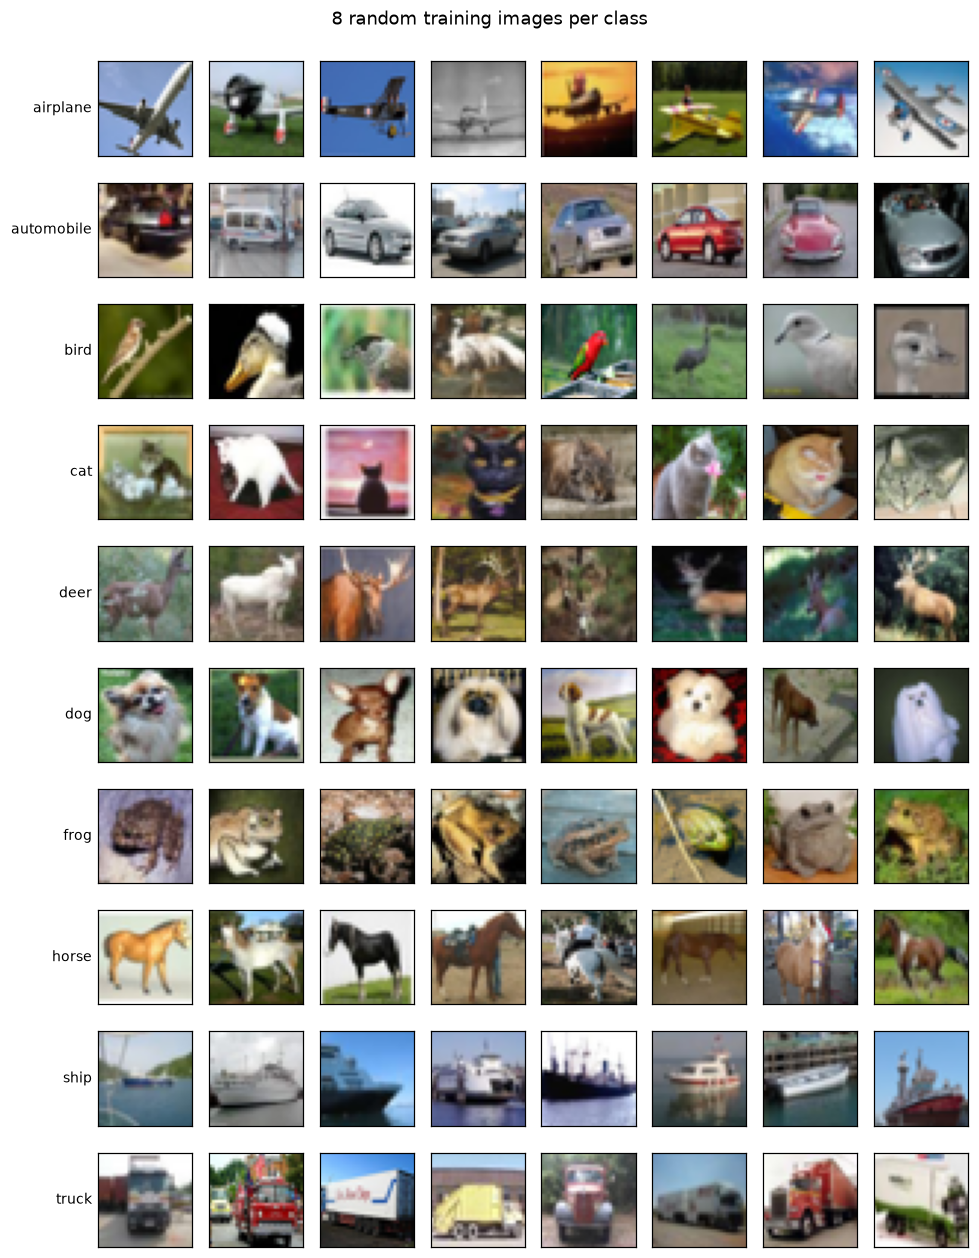

In [3]:
fig, axes = plt.subplots(10, 8, figsize=(9, 11.5))
for c in range(10):
    idx = rng.choice(np.where(y_train_full == c)[0], 8, replace=False)
    for j, i in enumerate(idx):
        ax = axes[c, j]; ax.imshow(x_train_full[i]); ax.set_xticks([]); ax.set_yticks([])
        if j == 0: ax.set_ylabel(CLASSES[c], rotation=0, ha="right", va="center", fontsize=9)
plt.suptitle("8 random training images per class", y=0.995)
plt.tight_layout(); plt.savefig(FIG / "01_preview_grid.png", bbox_inches="tight"); plt.show()

The images are indeed tiny (Karpathy measured ~94% human accuracy on them).
Objects appear in different poses, scales and backgrounds: a model must be invariant to position and
partly to scale. Birds/airplanes share sky backgrounds; ships/airplanes share blue; cats/dogs share fur texture.

## 3. Exploratory data analysis

Questions and expectations **before** looking:
1. *Class distribution* — expected perfectly balanced (5 000 / 1 000 per class).
2. *Image sizes* — expected all 32×32×3, no need to resize.
3. *Pixel statistics* — expected mean around 0.45–0.5 with a slight blue bias (sky, sea).
4. *Per-class colour* — expected ships/airplanes bluer, frogs/deer greener and darker.
5. *Duplicates / leakage* — expected few or no exact duplicates between train and test.

,train,test,train_%,test_%
airplane,5000,1000,10.0,10.0
automobile,5000,1000,10.0,10.0
bird,5000,1000,10.0,10.0
cat,5000,1000,10.0,10.0
deer,5000,1000,10.0,10.0
dog,5000,1000,10.0,10.0
frog,5000,1000,10.0,10.0
horse,5000,1000,10.0,10.0
ship,5000,1000,10.0,10.0
truck,5000,1000,10.0,10.0


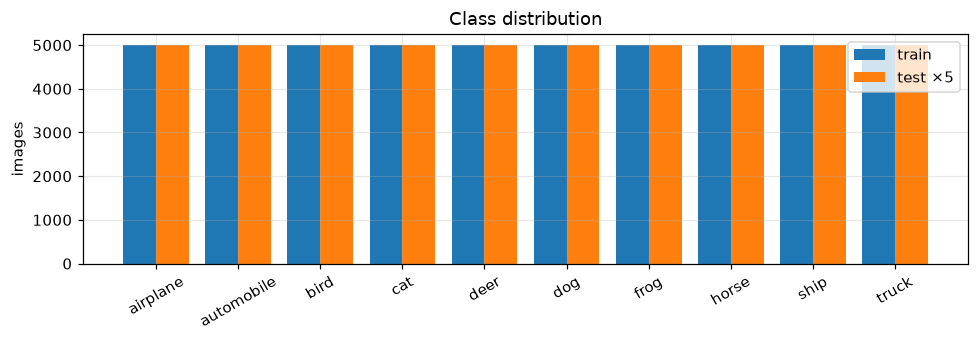

In [4]:
dist = pd.DataFrame({
    "train": np.bincount(y_train_full, minlength=10),
    "test": np.bincount(y_test, minlength=10)}, index=CLASSES)
dist["train_%"] = (dist["train"] / dist["train"].sum() * 100).round(2)
dist["test_%"] = (dist["test"] / dist["test"].sum() * 100).round(2)
dist.to_csv(TAB / "01_class_distribution.csv"); display(dist)

fig, ax = plt.subplots(figsize=(9, 3.2))
xs = np.arange(10)
ax.bar(xs - 0.2, dist["train"], 0.4, label="train"); ax.bar(xs + 0.2, dist["test"] * 5, 0.4, label="test ×5")
ax.set_xticks(xs, CLASSES, rotation=30); ax.set_ylabel("images"); ax.legend(); ax.set_title("Class distribution")
plt.tight_layout(); plt.savefig(FIG / "02_class_distribution.png"); plt.show()

**1.** Perfectly balanced: exactly 5 000 train and 1 000 test images per class. No class weighting or resampling is needed, and accuracy is an honest metric (a random guess gives 10%).

In [5]:
shapes = pd.Series([im.shape for im in x_train_full[:]] + [im.shape for im in x_test]).value_counts()
print("unique image shapes (H, W, C):"); print(shapes.to_string())
print("pixel value range:", x_train_full.min(), "…", x_train_full.max(), "| dtype:", x_train_full.dtype)
mb = (x_train_full.nbytes + x_test.nbytes) / 2**20
print(f"memory as uint8: {mb:.0f} MB; as float32: {mb*4:.0f} MB")

unique image shapes (H, W, C):
(32, 32, 3)    60000
pixel value range: 0 … 255 | dtype: uint8
memory as uint8: 176 MB; as float32: 703 MB


**2.** All 60 000 images are 32×32×3 uint8 (0…255). No resizing needed; the whole dataset fits into GPU memory as float32 (~700 MB), so training does not need a disk data loader.

,mean,std
R,0.4914,0.2470
G,0.4822,0.2435
B,0.4465,0.2616


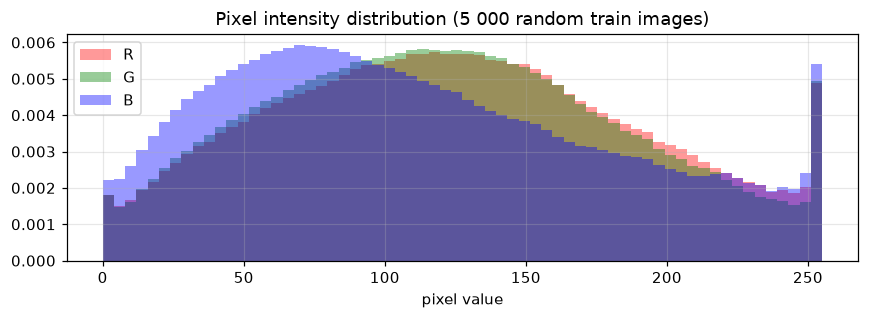

In [6]:
mean, std = channel_stats(x_train_full)
pix = pd.DataFrame({"mean": mean, "std": std}, index=["R", "G", "B"]).round(4)
display(pix)
sample = x_train_full[rng.choice(len(x_train_full), 5000, replace=False)]
fig, ax = plt.subplots(figsize=(8, 3))
for ch, col in enumerate(["red", "green", "blue"]):
    ax.hist(sample[..., ch].ravel(), bins=64, color=col, alpha=0.4, density=True, label="RGB"[ch])
ax.set_xlabel("pixel value"); ax.set_title("Pixel intensity distribution (5 000 random train images)"); ax.legend()
plt.tight_layout(); plt.savefig(FIG / "03_pixel_hist.png"); plt.show()

**3.** Means are ≈0.49/0.48/0.45 (R/G/B), std ≈0.25. Unlike the expectation, blue is slightly *lower* on average,
red a bit higher. Histograms are wide, with peaks near 0 and 255 (saturated sky, dark backgrounds).
These per-channel mean/std (computed on the training part only) are used for **standardisation** in §4.

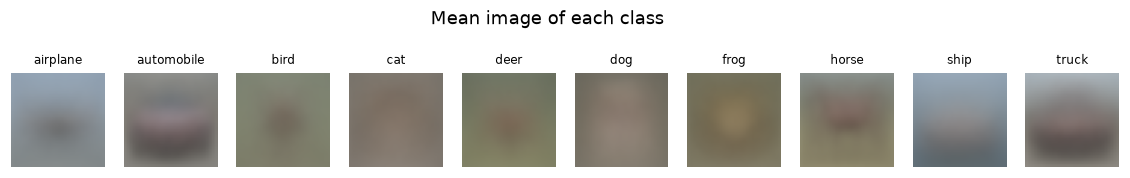

,R,G,B,brightness,contrast(std within image)
class,,,,,
airplane,0.526,0.561,0.590,0.558,0.204
automobile,0.472,0.455,0.447,0.458,0.237
bird,0.489,0.492,0.425,0.468,0.182
cat,0.496,0.457,0.416,0.456,0.217
deer,0.472,0.465,0.379,0.438,0.179
dog,0.500,0.465,0.417,0.460,0.217
frog,0.470,0.439,0.346,0.418,0.187
horse,0.502,0.480,0.417,0.466,0.221
ship,0.490,0.525,0.555,0.523,0.216


In [7]:
rows = []
fig, axes = plt.subplots(1, 10, figsize=(13, 1.8))
for c in range(10):
    xc = x_train_full[y_train_full == c].astype(np.float32) / 255
    axes[c].imshow(xc.mean(0)); axes[c].set_title(CLASSES[c], fontsize=8); axes[c].axis("off")
    m = xc.mean((0, 1, 2))
    rows.append({"class": CLASSES[c], "R": m[0], "G": m[1], "B": m[2],
                 "brightness": xc.mean(), "contrast(std within image)": xc.std((1, 2, 3)).mean()})
plt.suptitle("Mean image of each class", y=1.05)
plt.savefig(FIG / "04_mean_images.png", bbox_inches="tight"); plt.show()
per_class = pd.DataFrame(rows).set_index("class").round(3)
per_class.to_csv(TAB / "02_per_class_colour.csv"); display(per_class)

**4.** The mean images are blurry blobs, but already informative: airplane and ship have a blue background,
deer/frog/bird are green-brown in the centre, automobile/truck have a dark-centred shape. So colour alone
already carries some class information — a reason why even an MLP scores well above 10%. But the mean images
for cat, dog, horse, deer look very similar: shape and texture are needed to separate them, which is what convolutions learn.

In [8]:
def hashes(x):
    return np.array([hashlib.md5(im.tobytes()).hexdigest() for im in x])
h_tr, h_te = hashes(x_train_full), hashes(x_test)
dup_train = len(h_tr) - len(set(h_tr))
dup_test = len(h_te) - len(set(h_te))
overlap = len(set(h_tr) & set(h_te))
dups = pd.DataFrame({"check": ["exact duplicates inside train", "exact duplicates inside test",
                               "test images identical to a train image"],
                     "count": [dup_train, dup_test, overlap]})
dups.to_csv(TAB / "03_duplicates.csv", index=False); display(dups)

,check,count
0,exact duplicates inside train,0
1,exact duplicates inside test,0
2,test images identical to a train image,0


**5.** Exact (byte-identical) duplicates are practically absent, so there is no direct train→test leakage.
(Barz & Denzler, 2020, showed ~3% of CIFAR-10 test images have *near*-duplicates in train; that is a known
limitation of the benchmark, not something introduced here.)

**EDA summary.** Balanced, clean, fixed-size data → the difficulty is purely visual: small resolution,
large intra-class variation, similar classes (cat/dog, automobile/truck). Preprocessing needed:
scaling + standardisation, and augmentation to fight overfitting on only 5 000 images per class.

## 4. Preprocessing

1. **Split** train → 45 000 train + 5 000 validation, stratified by class.
2. **Scaling and standardisation**: `x/255`, then `(x − mean)/std` per channel. The reference code only divides by 255;
   standardising centres inputs around 0, which keeps early-layer activations well-scaled and speeds up training.
   Mean/std are fitted on the 45 000 training images only (no leakage).
3. **Augmentation** (train only, generated on the fly on the GPU): random crop 32×32 from the image padded by
   4 px (reflect) + random horizontal flip. A cat shifted by 3 px or mirrored is still a cat, so the network
   effectively sees new images each epoch. Vertical flips are *not* used (upside-down ships/cars do not occur in test).
4. **Feature extraction**: CNNs learn their own filters, so no hand-crafted features are fed in.
   §5 shows hand-made filters (edges, blur) computed with my own convolution to illustrate what the first layer learns.

In [9]:
x_tr, x_va, y_tr, y_va = split_train_val(x_train_full, y_train_full, seed=SEED)
split = pd.DataFrame({"train": np.bincount(y_tr), "val": np.bincount(y_va), "test": np.bincount(y_test)}, index=CLASSES)
split.loc["total"] = split.sum()
split.to_csv(TAB / "04_splits.csv"); display(split.T)
data = prepare_data("cifar10", DEVICE)
print("train tensor:", tuple(data["x_train"].shape), "mean after standardisation:",
      data["x_train"].mean((0, 2, 3)).cpu().numpy().round(3), "std:", data["x_train"].std((0, 2, 3)).cpu().numpy().round(3))

,airplane,automobile,bird,cat,deer,dog,frog,horse,ship,truck,total
train,4500,4500,4500,4500,4500,4500,4500,4500,4500,4500,45000
val,500,500,500,500,500,500,500,500,500,500,5000
test,1000,1000,1000,1000,1000,1000,1000,1000,1000,1000,10000


train tensor: (45000, 3, 32, 32) mean after standardisation: [ 0. -0.  0.] std: [1. 1. 1.]


Every split has exactly 10% per class. After standardisation each channel of the training set has mean 0 and std 1.

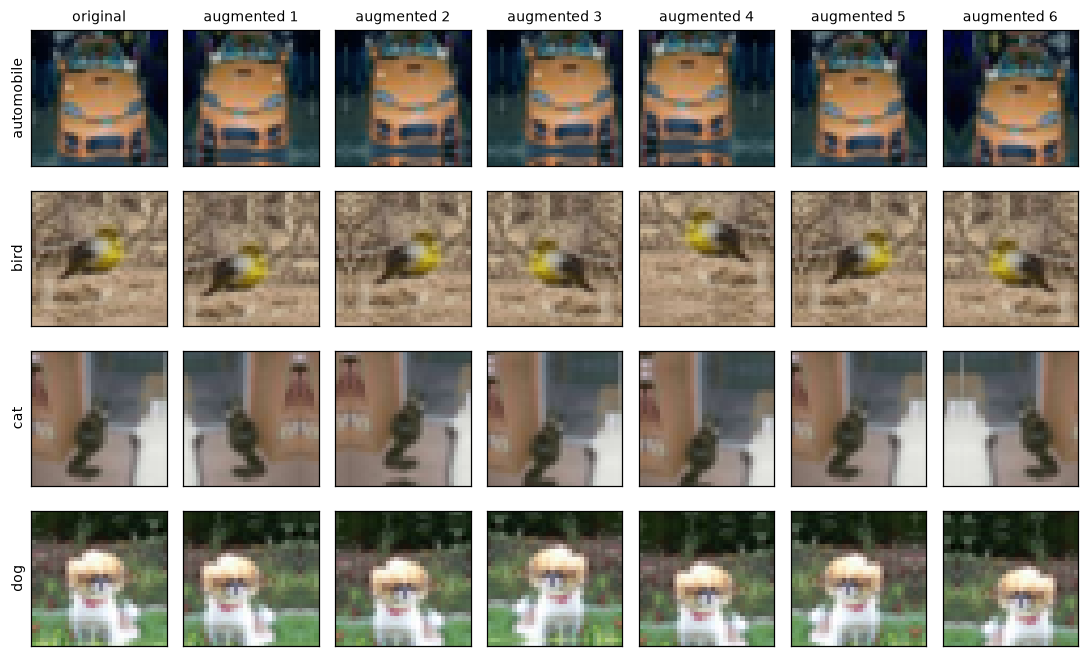

In [10]:
def denorm(t):
    m = torch.tensor(data["mean"], device=t.device).view(3, 1, 1); s = torch.tensor(data["std"], device=t.device).view(3, 1, 1)
    return (t * s + m).clamp(0, 1).permute(1, 2, 0).cpu().numpy()

torch.manual_seed(0)
ids = [0, 7, 21, 33]
fig, axes = plt.subplots(len(ids), 7, figsize=(10, 6.2))
for r, i in enumerate(ids):
    orig = data["x_train"][i:i + 1]
    axes[r, 0].imshow(denorm(orig[0])); axes[r, 0].set_title("original" if r == 0 else "", fontsize=9)
    axes[r, 0].set_ylabel(CLASSES[int(data["y_train"][i])], fontsize=9)
    for j in range(1, 7):
        axes[r, j].imshow(denorm(augment(orig)[0]));
        if r == 0: axes[r, j].set_title(f"augmented {j}", fontsize=9)
for ax in axes.flat: ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.savefig(FIG / "05_augmentation.png"); plt.show()

The augmented copies stay clearly recognisable: shifts of up to 4 px, reflected borders and mirroring. Labels are preserved, so augmentation adds data without adding label noise.

## 5. Convolution from scratch (theory check)

`src/scratch_conv.py` implements 1D convolution (valid / same / full), the CNN 2D convolution layer,
max pooling and the output-size formula $\;O = \lfloor (W - K + 2P)/S \rfloor + 1$ in plain NumPy.
First, a 1D reference example: input `[1,2,3,4,5]`, kernel `[2,0,1]`.

In [11]:
for mode, expected in [("valid", [7, 10, 13]), ("same", [4, 7, 10, 13, 4]), ("full", [2, 4, 7, 10, 13, 4, 5])]:
    out = sc.conv1d([1, 2, 3, 4, 5], [2, 0, 1], mode)
    print(f"{mode:5s} -> {out.astype(int).tolist()}  expected: {expected}  match: {out.astype(int).tolist() == expected}")
print("np.convolve full:", np.convolve([1, 2, 3, 4, 5], [2, 0, 1]).tolist())

valid -> [7, 10, 13]  expected: [7, 10, 13]  match: True
same  -> [4, 7, 10, 13, 4]  expected: [4, 7, 10, 13, 4]  match: True
full  -> [2, 4, 7, 10, 13, 4, 5]  expected: [2, 4, 7, 10, 13, 4, 5]  match: True
np.convolve full: [2, 4, 7, 10, 13, 4, 5]


All three modes reproduce the reference values and NumPy. Now the 2D CNN layer against `torch.nn.functional.conv2d` (note: CNN layers compute *cross-correlation*, the kernel is not flipped — the flip does not matter because the kernel is learned).

In [12]:
xr = np.random.default_rng(1).normal(size=(3, 7, 7)); wr = np.random.default_rng(2).normal(size=(4, 3, 3, 3)); br = np.ones(4)
rows = []
for s, p in [(1, 0), (2, 0), (1, 1), (2, 1)]:
    mine = sc.conv2d(xr, wr, br, stride=s, padding=p)
    ref = F.conv2d(torch.tensor(xr)[None], torch.tensor(wr), torch.tensor(br), stride=s, padding=p)[0].numpy()
    rows.append({"input": "7x7", "kernel": "3x3", "stride": s, "padding": p, "formula": sc.output_size(7, 3, s, p),
                 "my output": f"{mine.shape[1]}x{mine.shape[2]}", "max |diff| vs torch": np.abs(mine - ref).max()})
pool_ok = np.allclose(sc.maxpool2d(xr), F.max_pool2d(torch.tensor(xr), 2).numpy())
display(pd.DataFrame(rows)); print("max pooling 2x2 matches torch:", pool_ok)

,input,kernel,stride,padding,formula,my output,max |diff| vs torch
0,7x7,3x3,1,0,5,5x5,3.552714e-15
1,7x7,3x3,2,0,3,3x3,3.552714e-15
2,7x7,3x3,1,1,7,7x7,3.552714e-15
3,7x7,3x3,2,1,4,4x4,1.998401e-15


max pooling 2x2 matches torch: True


Identical to PyTorch up to floating-point error, and the output sizes follow the formula (7×7, stride 1, no padding → 5×5; stride 2 → 3×3; padding 1 = *same* → 7×7).

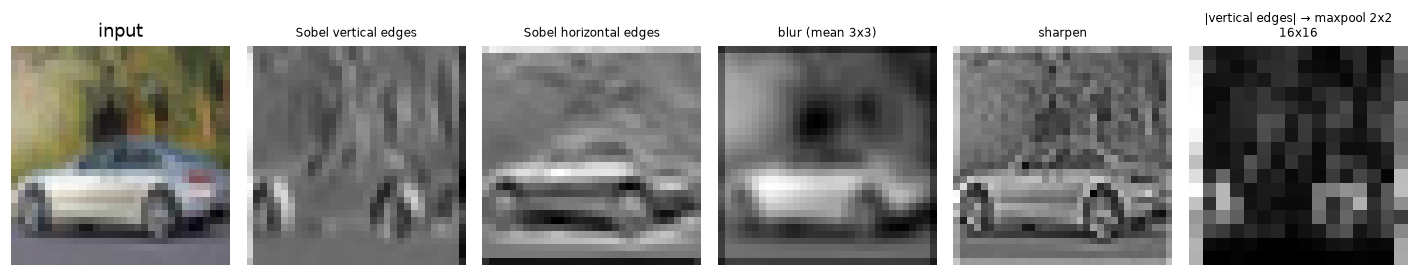

In [13]:
img = x_train_full[np.where(y_train_full == 1)[0][3]].astype(float) / 255     # an automobile
gray = img.mean(2)[None]                                                       # (1, 32, 32)
kernels = {"Sobel vertical edges": [[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]],
           "Sobel horizontal edges": [[-1, -2, -1], [0, 0, 0], [1, 2, 1]],
           "blur (mean 3x3)": np.ones((3, 3)) / 9, "sharpen": [[0, -1, 0], [-1, 5, -1], [0, -1, 0]]}
fig, axes = plt.subplots(1, 6, figsize=(13, 2.5))
axes[0].imshow(img); axes[0].set_title("input")
fm = sc.conv2d(gray, np.array(kernels["Sobel vertical edges"], float)[None, None], padding=1)
for ax, (name, k) in zip(axes[1:5], kernels.items()):
    ax.imshow(sc.conv2d(gray, np.array(k, float)[None, None], padding=1)[0], cmap="gray"); ax.set_title(name, fontsize=8)
axes[5].imshow(sc.maxpool2d(np.abs(fm))[0], cmap="gray"); axes[5].set_title("|vertical edges| → maxpool 2x2\n16x16", fontsize=8)
for ax in axes: ax.axis("off")
plt.tight_layout(); plt.savefig(FIG / "06_handmade_filters.png"); plt.show()

Hand-made 3×3 kernels already extract edges, smooth or sharpen; max pooling halves the resolution while keeping the strongest responses. A CNN **learns** such kernels (and many more) by gradient descent instead of having them designed — this is the 'feature extraction' part of the network.

## 6. Baseline models

Four reference architectures, trained identically: Adam (lr = 1e-3), batch 128, cross-entropy,
**20 epochs** (instead of 5 in the reference setup, to see the full learning curves; 20 is a compute compromise — the Mac ran in Low Power Mode), no augmentation.
The weights from the epoch with the best validation accuracy are kept.

| Model | Structure |
|---|---|
| `e1_mlp` | flatten 3072 → Dense 1024 → Dense 512 → 10 |
| `e2_simple_cnn` | Conv32 (valid) → MaxPool → Conv64 → MaxPool → Dense 64 → 10 |
| `e3_deep_cnn` | 3 blocks × [Conv, BN, Conv, BN, MaxPool, Dropout] (32-64-128) → Dense 256 + BN + Dropout 0.5 → 10 |
| `e4_se_cnn` | Conv32 → MaxPool → **SE** → Conv64 → MaxPool → **SE** → Dense 128 → Dropout → 10 |

Training is cached: `run_experiment` loads weights from `weights/` and history from `results/logs/` if they exist.

In [14]:
for cfg in BASELINES + ABLATION + FINAL:
    m = build_model(cfg["arch"], 10, **cfg.get("model_kwargs", {}))
    print(f"{cfg['name']:28s} params = {count_params(m):>10,}")

e1_mlp                       params =  3,676,682
e2_simple_cnn                params =    167,562
e3_deep_cnn                  params =    815,530
e4_se_cnn                    params =    546,486
a1_deep_plain                params =    814,122
a2_deep_bn                   params =    815,530
a3_deep_dropout              params =    814,122
a4_deep_aug                  params =    815,530
a5_deep_aug_se               params =    821,158
a6_deep_aug_onecycle         params =    815,530
a7_deep_wide_aug_onecycle    params =  2,199,114
f1_resnet9                   params =  1,655,166


Output size check for the simple CNN (formula from §5): 32 →conv(valid) 30 →pool 15 →conv 13 →pool 6, so Flatten gives 6·6·64 = 2304 inputs to Dense(64) — matches the layer shapes in `src/models.py`.

,params,best_epoch,best_val_acc,final_train_acc,final_val_acc,overfit_gap,min_val_loss,test_acc,test_loss,train_minutes
name,,,,,,,,,,
e1_mlp,3676682,11,0.5282,0.8586,0.5158,0.3428,1.4149,0.5297,1.6120,0.9647
e2_simple_cnn,167562,13,0.7094,0.8887,0.6960,0.1927,0.8716,0.7054,0.9311,3.5643
e3_deep_cnn,815530,20,0.8532,0.8940,0.8532,0.0408,0.4501,0.8516,0.4703,14.2860
e4_se_cnn,546486,18,0.7242,0.8492,0.7204,0.1288,0.8280,0.7270,0.9193,5.0543


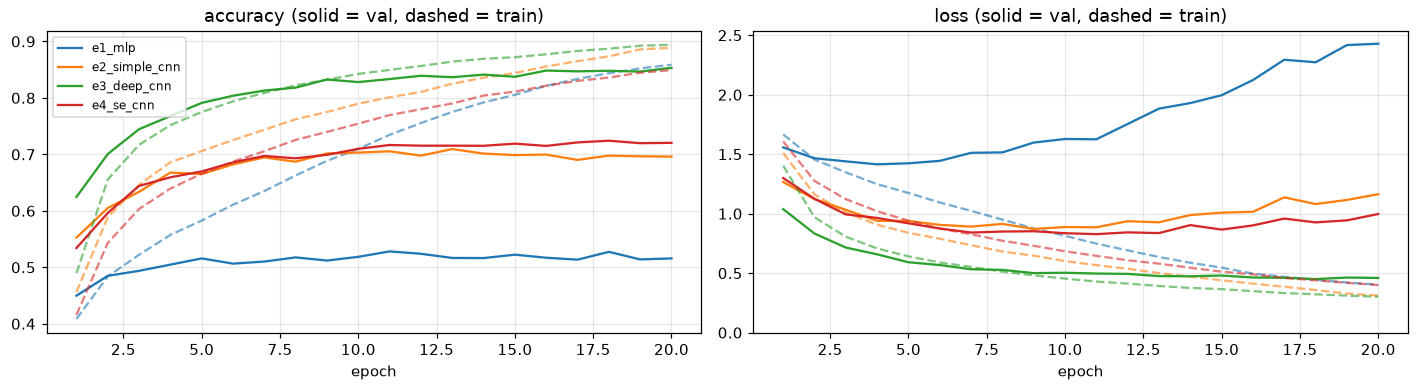

In [15]:
RESULTS = {}
def run(cfgs):
    for cfg in cfgs:
        model, hist, summ = run_experiment(cfg, data, verbose=False)
        RESULTS[cfg["name"]] = {"model": model, "hist": pd.DataFrame(hist), "summary": summ}

def summary_table(names):
    t = pd.DataFrame([RESULTS[n]["summary"] for n in names]).set_index("name")
    t["overfit_gap"] = t["final_train_acc"] - t["final_val_acc"]
    cols = ["params", "best_epoch", "best_val_acc", "final_train_acc", "final_val_acc", "overfit_gap",
            "min_val_loss", "test_acc", "test_loss", "train_minutes"]
    return t[cols]

def plot_curves(names, title, fname):
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    for i, n in enumerate(names):
        h = RESULTS[n]["hist"]; c = f"C{i}"
        axes[0].plot(h.epoch, h.train_acc, c, ls="--", alpha=0.6); axes[0].plot(h.epoch, h.val_acc, c, label=n)
        axes[1].plot(h.epoch, h.train_loss, c, ls="--", alpha=0.6); axes[1].plot(h.epoch, h.val_loss, c, label=n)
    axes[0].set_title("accuracy (solid = val, dashed = train)"); axes[1].set_title("loss (solid = val, dashed = train)")
    axes[1].set_ylim(0, None); axes[0].set_xlabel("epoch"); axes[1].set_xlabel("epoch"); axes[0].legend(fontsize=8)
    fig.suptitle(title); plt.tight_layout(); plt.savefig(FIG / fname); plt.show()

run(BASELINES)
baseline_tab = summary_table([c["name"] for c in BASELINES])
baseline_tab.to_csv(TAB / "05_baseline_models.csv"); display(baseline_tab.round(4))
plot_curves([c["name"] for c in BASELINES], "Baseline models (Adam 1e-3, no augmentation, 20 epochs)", "07_baseline_curves.png")

**Interpretation.**
- **MLP: 52.8% val / 53.0% test.** Much better than chance (10%), because colour and rough layout already say a lot (§3). But it overfits from the start: train accuracy reaches 86% while val loss is minimal at epoch 4 and then *grows* from 1.41 to 2.4. 3.7 M parameters with no notion of neighbouring pixels memorise the training set.
- **Simple CNN: 70.9% / 70.5%** with **22× fewer parameters** (168 k). Weight sharing and locality are the right prior for images: +18 percentage points over the MLP. It also overfits (val loss minimal at epoch 9, train–val gap 19 pp at the end).
- **Deep CNN (BN + Dropout): 85.3% / 85.2%**, the best baseline model. Its train and val curves stay close (gap 4 pp), val loss keeps decreasing — it is still improving at epoch 20, so it is regularised rather than overfitting.
- **SE-CNN: 72.4% / 72.7%.** A 2-conv network with channel attention that also differs from the simple CNN in padding, head width and Dropout, so the +1.5 pp between them does not isolate attention. It stays far below the deep CNN: attention re-weights features, it cannot replace depth (only two conv layers ⇒ small receptive field). It overfits too: no BN, one Dropout.

Ranking by test accuracy matches the validation ranking, so the validation set is a reliable guide.

## 7. Variations: what each technique adds (ablation)

Base: the deep baseline CNN. Each experiment changes **one technique** relative to its base run; the switch to SGD + OneCycle also adds weight decay 5e-4:

| Experiment | Change |
|---|---|
| `a1_deep_plain` | deep CNN without BatchNorm and without Dropout |
| `a2_deep_bn` | + BatchNorm only |
| `a3_deep_dropout` | + Dropout only (no BN) |
| `e3_deep_cnn` | BatchNorm + Dropout (baseline) |
| `a4_deep_aug` | e3 + data augmentation |
| `a5_deep_aug_se` | a4 + SE (channel attention) block after each conv block |
| `a6_deep_aug_onecycle` | a4 with SGD-Nesterov + OneCycle learning-rate schedule instead of constant Adam, plus weight decay 5e-4 |
| `a7_deep_wide_aug_onecycle` | a6 with 2× wider layers (64-128-256) |

,params,best_epoch,best_val_acc,final_train_acc,final_val_acc,overfit_gap,min_val_loss,test_acc,test_loss,train_minutes
name,,,,,,,,,,
a1_deep_plain,814122,12,0.7768,0.9766,0.7642,0.2124,0.6773,0.7762,0.9774,10.4988
a2_deep_bn,815530,17,0.8276,0.9886,0.8168,0.1718,0.5651,0.8296,0.8018,14.1825
a3_deep_dropout,814122,20,0.8072,0.8214,0.8072,0.0142,0.5525,0.8124,0.5547,10.6316
e3_deep_cnn,815530,20,0.8532,0.8940,0.8532,0.0408,0.4501,0.8516,0.4703,14.2860
a4_deep_aug,815530,20,0.8658,0.8364,0.8658,-0.0294,0.3894,0.8661,0.3942,10.5302
a5_deep_aug_se,821158,20,0.8642,0.8383,0.8642,-0.0259,0.3894,0.8644,0.3912,14.4767
a6_deep_aug_onecycle,815530,20,0.8788,0.8555,0.8788,-0.0233,0.3515,0.8775,0.3629,7.4289
a7_deep_wide_aug_onecycle,2199114,20,0.9048,0.9142,0.9048,0.0094,0.2785,0.9055,0.2835,25.6851


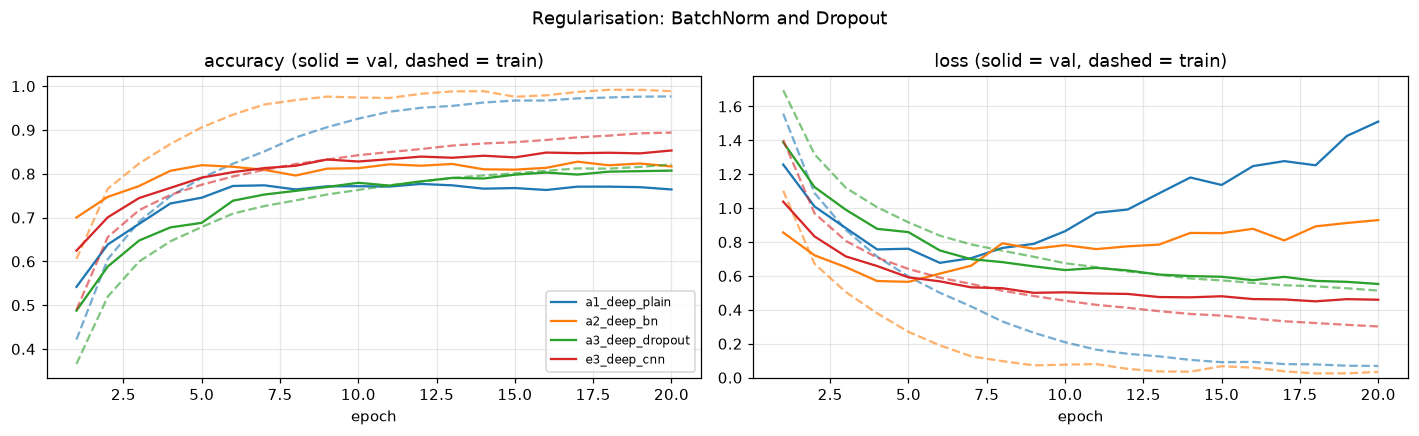

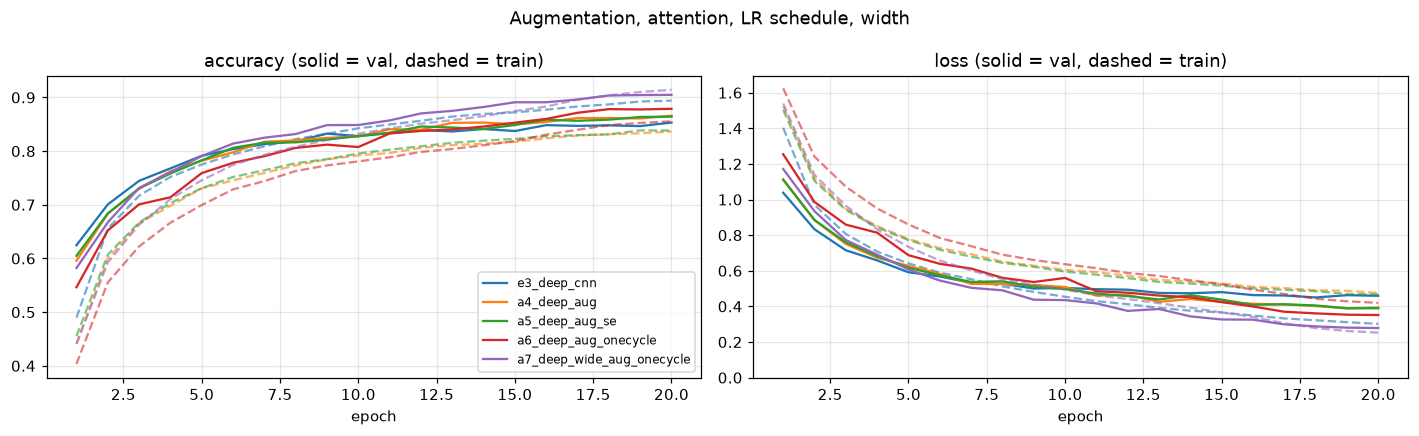

In [16]:
run(ABLATION)
abl_names = ["a1_deep_plain", "a2_deep_bn", "a3_deep_dropout", "e3_deep_cnn", "a4_deep_aug",
             "a5_deep_aug_se", "a6_deep_aug_onecycle", "a7_deep_wide_aug_onecycle"]
abl_tab = summary_table(abl_names)
abl_tab.to_csv(TAB / "06_ablation.csv"); display(abl_tab.round(4))
plot_curves(abl_names[:4], "Regularisation: BatchNorm and Dropout", "08_ablation_regularisation.png")
plot_curves(["e3_deep_cnn", "a4_deep_aug", "a5_deep_aug_se", "a6_deep_aug_onecycle", "a7_deep_wide_aug_onecycle"],
            "Augmentation, attention, LR schedule, width", "09_ablation_aug_schedule.png")

**Interpretation.**
Validation-accuracy deltas (the std error of an accuracy on 5 000 images is ≈0.5 pp, so differences below ~1 pp are noise):

| Step | val acc | Δ | What the curves show |
|---|---|---|---|
| plain deep CNN | 77.7% | — | train 98%, val loss explodes after epoch 6 (0.68 → 1.51): classic overfitting |
| + BatchNorm only | 82.8% | +5.1 | faster and higher, but still memorises (train 99%, val loss grows) |
| + Dropout only | 80.7% | +3.0 | overfitting gone (gap 1 pp), but learns slowly |
| BN + Dropout (baseline) | 85.3% | +7.6 vs plain | BN speeds up, Dropout prevents memorising — they complement each other |
| + augmentation | 86.6% | +1.3 | train acc now *below* val (harder augmented data + dropout); still improving at epoch 20 |
| + SE attention | 86.4% | −0.2 | no measurable gain in an already deep, regularised net |
| Adam → SGD + OneCycle (+ weight decay) | 87.9% | +1.3 | lower val loss (0.35 vs 0.39) |
| 2× wider (2.2 M params) | 90.5% | +2.6 | more filters per layer = more features; the biggest single gain after BN+Dropout |

**Biggest contributors:** BatchNorm + Dropout together (+7.6 pp) and model capacity once overfitting is controlled (+2.6 pp). Augmentation gives a modest +1.3 pp in 20 epochs, but it changes the regime: the augmented models are not overfitting at all, so they would keep improving with more epochs, while non-augmented ones had already peaked.

## 8. Final model: ResNet-9 with SE attention

Combining what helped, plus residual connections (the "stack more layers" idea done safely):

- `conv(64) → conv(128)+pool → Residual(128) → conv(256)+pool → conv(512)+pool → Residual(512) → global max-pool → Dropout → Dense(10)`,
  here at half width (32 … 256 channels, 1.7 M parameters) so that it trains in reasonable time on the M4 GPU;
- each residual block computes $y = x + \text{SE}(F(x))$: the skip connection lets the gradient flow directly,
  SE re-weights channels;
- Conv → BatchNorm → ReLU order (normalise before the non-linearity);
- augmentation (crop + flip), SGD-Nesterov + OneCycle (max lr 0.1, weight decay 5e-4), label smoothing 0.1, 30 epochs.

,params,best_epoch,best_val_acc,final_train_acc,final_val_acc,overfit_gap,min_val_loss,test_acc,test_loss,train_minutes
name,,,,,,,,,,
f1_resnet9,1655166,30,0.9296,0.9796,0.9296,0.05,0.2917,0.9257,0.3062,21.7339


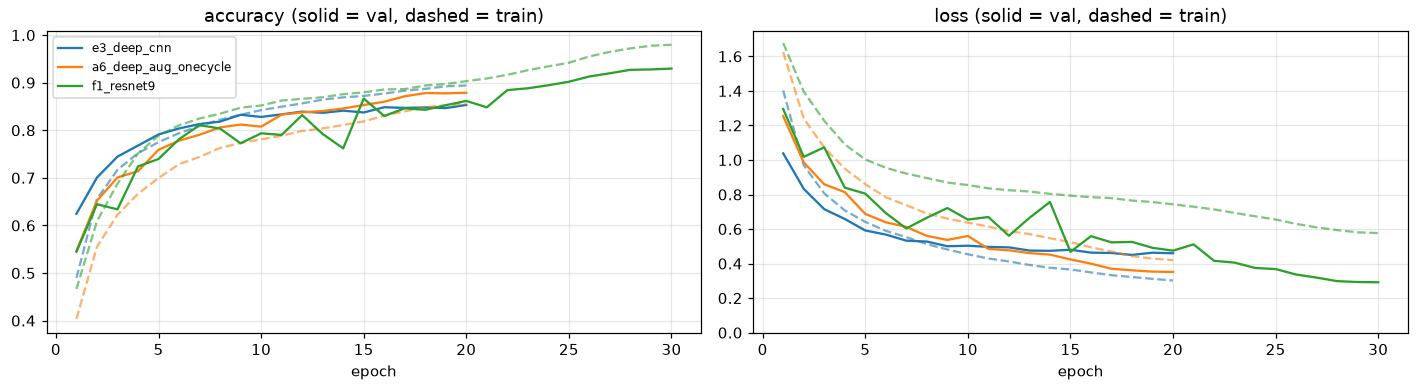

In [17]:
run(FINAL)
final_tab = summary_table(["f1_resnet9"]); display(final_tab.round(4))
plot_curves(["e3_deep_cnn", "a6_deep_aug_onecycle", "f1_resnet9"], "Baseline deep CNN vs best ablation vs final ResNet-9", "10_final_curves.png")

**Interpretation.**
**ResNet-9: 93.0% validation, 92.6% test** — +7.4 pp over the best baseline model and +2.0 pp over the wide CNN, with fewer parameters than the wide CNN (1.66 M vs 2.2 M). Architecture, label smoothing, max learning rate and epoch count all change in this run, so the gain belongs to the whole recipe. Residual connections are meant to let a network be this deep (8 conv layers in the main path) without the optimisation problems of a plain stack. The OneCycle schedule is visible in the curves: val accuracy stalls around 79–83% while the learning rate is high (epochs 7–16), then climbs from 85% to 93% in the last third as the lr decays. Train accuracy (98%, measured on augmented images) is above val, so with more epochs or stronger augmentation (e.g. Cutout) the model could still improve. The test result (92.6%) is close to the reported human level (~94%).

## 9. Comparison of all models

,params,best_epoch,best_val_acc,final_train_acc,final_val_acc,overfit_gap,min_val_loss,test_acc,test_loss,train_minutes
name,,,,,,,,,,
e1_mlp,3676682,11,0.5282,0.8586,0.5158,0.3428,1.4149,0.5297,1.6120,0.9647
e2_simple_cnn,167562,13,0.7094,0.8887,0.6960,0.1927,0.8716,0.7054,0.9311,3.5643
e4_se_cnn,546486,18,0.7242,0.8492,0.7204,0.1288,0.8280,0.7270,0.9193,5.0543
a1_deep_plain,814122,12,0.7768,0.9766,0.7642,0.2124,0.6773,0.7762,0.9774,10.4988
a3_deep_dropout,814122,20,0.8072,0.8214,0.8072,0.0142,0.5525,0.8124,0.5547,10.6316
a2_deep_bn,815530,17,0.8276,0.9886,0.8168,0.1718,0.5651,0.8296,0.8018,14.1825
e3_deep_cnn,815530,20,0.8532,0.8940,0.8532,0.0408,0.4501,0.8516,0.4703,14.2860
a5_deep_aug_se,821158,20,0.8642,0.8383,0.8642,-0.0259,0.3894,0.8644,0.3912,14.4767
a4_deep_aug,815530,20,0.8658,0.8364,0.8658,-0.0294,0.3894,0.8661,0.3942,10.5302


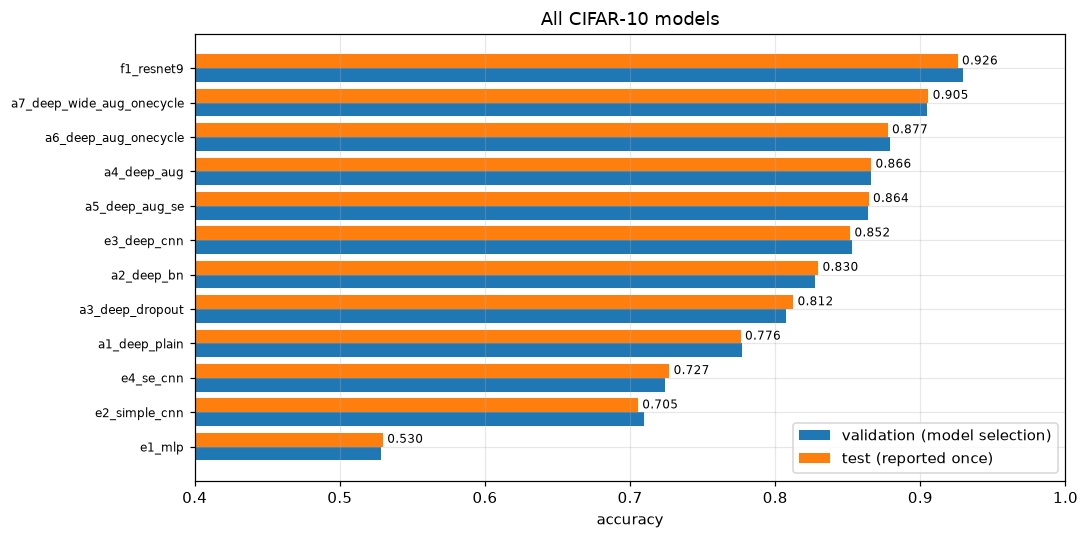

In [18]:
all_names = [c["name"] for c in BASELINES + ABLATION + FINAL]
comp = summary_table(all_names).sort_values("best_val_acc")
comp.to_csv(TAB / "07_all_models.csv"); display(comp.round(4))
fig, ax = plt.subplots(figsize=(10, 5))
ypos = np.arange(len(comp))
ax.barh(ypos - 0.2, comp["best_val_acc"], 0.4, label="validation (model selection)")
ax.barh(ypos + 0.2, comp["test_acc"], 0.4, label="test (reported once)")
for y, v in zip(ypos, comp["test_acc"]): ax.text(v + 0.003, y + 0.2, f"{v:.3f}", va="center", fontsize=8)
ax.set_yticks(ypos, comp.index, fontsize=8); ax.set_xlim(0.4, 1.0); ax.set_xlabel("accuracy"); ax.legend(loc="lower right")
ax.set_title("All CIFAR-10 models"); plt.tight_layout(); plt.savefig(FIG / "11_all_models.png"); plt.show()

Test accuracy follows validation accuracy everywhere (max difference 0.6 pp), so model selection on validation did not overfit the validation set. Progression: **MLP 53% → simple CNN 70.5% → baseline deep CNN 85.2% → + augmentation and OneCycle 87.8% → wider 90.6% → ResNet-9 92.6%.** Parameter count is not what decides: the MLP has the most parameters and is the worst; ResNet-9 has fewer parameters than the wide CNN and scores higher, although its training recipe differs too. The architecture's inductive bias (locality, weight sharing) and regularisation matter more than size.

## 10. Error analysis of the best model

Best model by **validation** accuracy (selected without looking at the test set). Here it is evaluated on the test set:
confusion matrix, per-class precision/recall, and the most confident mistakes.

best model: f1_resnet9 | test accuracy: 0.9257


,precision,recall,f1-score,support
airplane,0.927,0.942,0.935,1000.000
automobile,0.964,0.975,0.970,1000.000
bird,0.922,0.894,0.908,1000.000
cat,0.836,0.839,0.837,1000.000
deer,0.927,0.931,0.929,1000.000
dog,0.887,0.867,0.877,1000.000
frog,0.932,0.947,0.939,1000.000
horse,0.951,0.948,0.949,1000.000
ship,0.953,0.960,0.957,1000.000
truck,0.956,0.954,0.955,1000.000


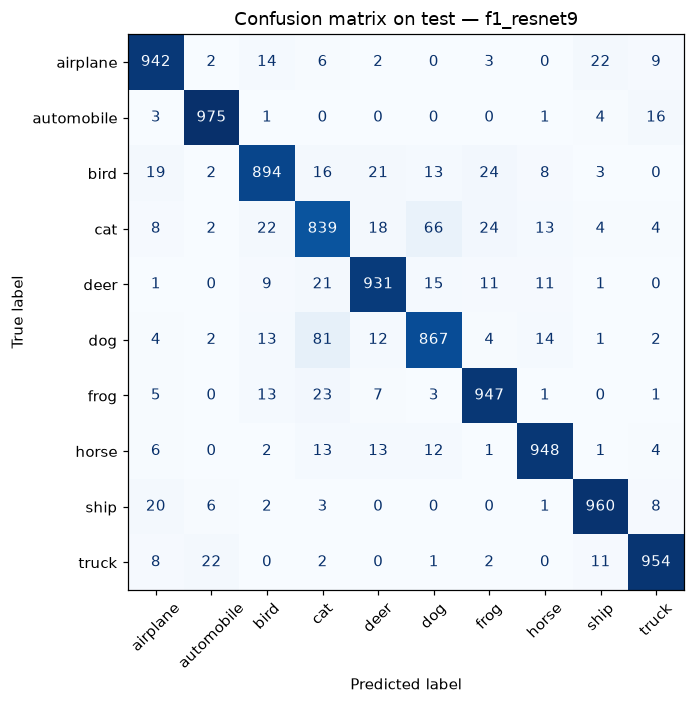

,true,predicted,count
0,dog,cat,81
1,cat,dog,66
2,bird,frog,24
3,cat,frog,24
4,frog,cat,23
5,airplane,ship,22
6,cat,bird,22
7,truck,automobile,22


In [19]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report
best_name = comp["best_val_acc"].idxmax(); best = RESULTS[best_name]["model"]
logits = predict_logits(best, data["x_test"]); probs = logits.softmax(1).cpu().numpy()
pred = probs.argmax(1); y_true = data["y_test"].cpu().numpy()
print("best model:", best_name, "| test accuracy:", (pred == y_true).mean().round(4))
rep = pd.DataFrame(classification_report(y_true, pred, target_names=CLASSES, output_dict=True)).T.round(3)
rep.to_csv(TAB / "08_per_class_report.csv"); display(rep)
cm = confusion_matrix(y_true, pred)
fig, ax = plt.subplots(figsize=(7.5, 6.5))
ConfusionMatrixDisplay(cm, display_labels=CLASSES).plot(ax=ax, cmap="Blues", colorbar=False, xticks_rotation=45)
ax.set_title(f"Confusion matrix on test — {best_name}"); ax.grid(False)
plt.tight_layout(); plt.savefig(FIG / "12_confusion_matrix.png"); plt.show()
pairs = [(CLASSES[i], CLASSES[j], cm[i, j]) for i in range(10) for j in range(10) if i != j]
top_conf = pd.DataFrame(sorted(pairs, key=lambda t: -t[2])[:8], columns=["true", "predicted", "count"])
top_conf.to_csv(TAB / "09_top_confusions.csv", index=False); display(top_conf)

Per-class recall ranges from **83.9% (cat)** to **97.5% (automobile)**. The hardest classes are the animals with similar texture and pose: cat (83.9%), dog (86.7%), bird (89.4%). The top confusions are **dog→cat (81) and cat→dog (66)** — together 147 of 743 errors (20%). Next: bird↔frog/cat (small brownish animals on grass), airplane→ship (blue background), truck→automobile (pickups and SUVs are on the border between the two classes). The vehicles and horse/ship are above 94%. These are exactly the pairs that looked similar in the EDA (mean images, colour table).

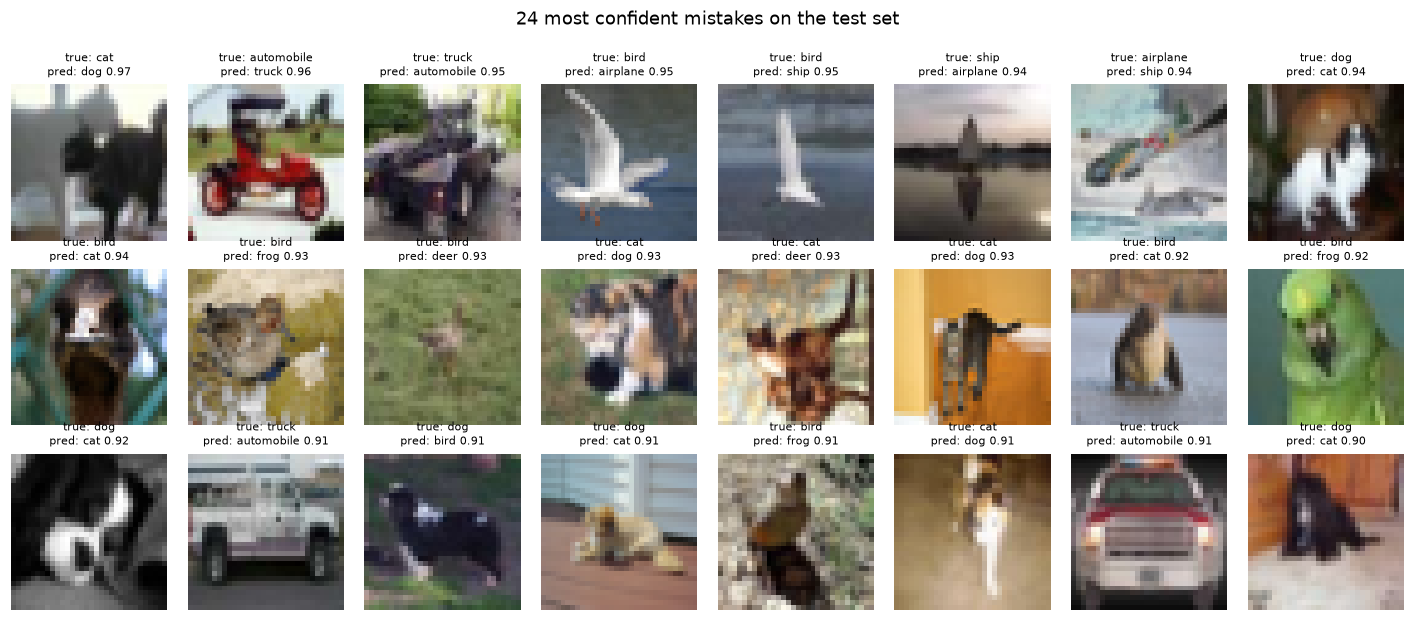

saved 24 images to results/samples/misclassified and review table results/review/misclassified.csv


In [20]:
wrong = np.where(pred != y_true)[0]
conf_wrong = wrong[np.argsort(-probs[wrong].max(1))][:24]          # most confident mistakes
fig, axes = plt.subplots(3, 8, figsize=(13, 5.6))
SAMPLES = ROOT / "results" / "samples" / "misclassified"; SAMPLES.mkdir(parents=True, exist_ok=True)
review = []
for ax, i in zip(axes.flat, conf_wrong):
    ax.imshow(x_test[i]); ax.axis("off")
    ax.set_title(f"true: {CLASSES[y_true[i]]}\npred: {CLASSES[pred[i]]} {probs[i].max():.2f}", fontsize=7.5)
    fname = f"test{i:05d}_true-{CLASSES[y_true[i]]}_pred-{CLASSES[pred[i]]}.png"
    plt.imsave(SAMPLES / fname, np.kron(x_test[i], np.ones((4, 4, 1), dtype=np.uint8)))   # 128x128 for viewing
    review.append({"file": fname, "true": CLASSES[y_true[i]], "pred": CLASSES[pred[i]],
                   "confidence": round(float(probs[i].max()), 3),
                   "what_to_check": "Is the true label correct? Is the image ambiguous even for a human?",
                   "verdict (model wrong / label wrong / ambiguous)": "", "comment": ""})
plt.suptitle("24 most confident mistakes on the test set", y=1.0); plt.tight_layout()
plt.savefig(FIG / "13_confident_mistakes.png", bbox_inches="tight"); plt.show()
(ROOT / "results" / "review").mkdir(exist_ok=True)
pd.DataFrame(review).to_csv(ROOT / "results" / "review" / "misclassified.csv", index=False)
print("saved", len(review), "images to", SAMPLES.relative_to(ROOT), "and review table results/review/misclassified.csv")

**Human check.** Accuracy cannot tell whether a mistake is the model's fault or an ambiguous / wrong label.
The 24 most confident mistakes are saved (upscaled ×4) in `results/samples/misclassified/`; the table
`results/review/misclassified.csv` asks for a verdict per image: *model wrong*, *label wrong* or *ambiguous*.
Looking at the grid above: several mistakes are understandable even for a human (a seagull over water predicted as *ship*, a red vintage car predicted as *truck*, pickups predicted as *automobile*, dark close-ups of cats and dogs). The verdict column is left for manual review.

## 11. What the network learned

1. First-layer filters (3×3×3 kernels shown as RGB patches).
2. Feature maps of one image after each block of the baseline deep CNN — from edges to abstract patterns.
3. 2-D t-SNE of the penultimate-layer features of the best model: are classes separated?

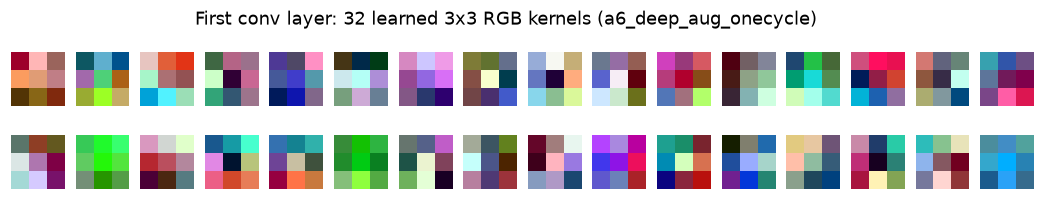

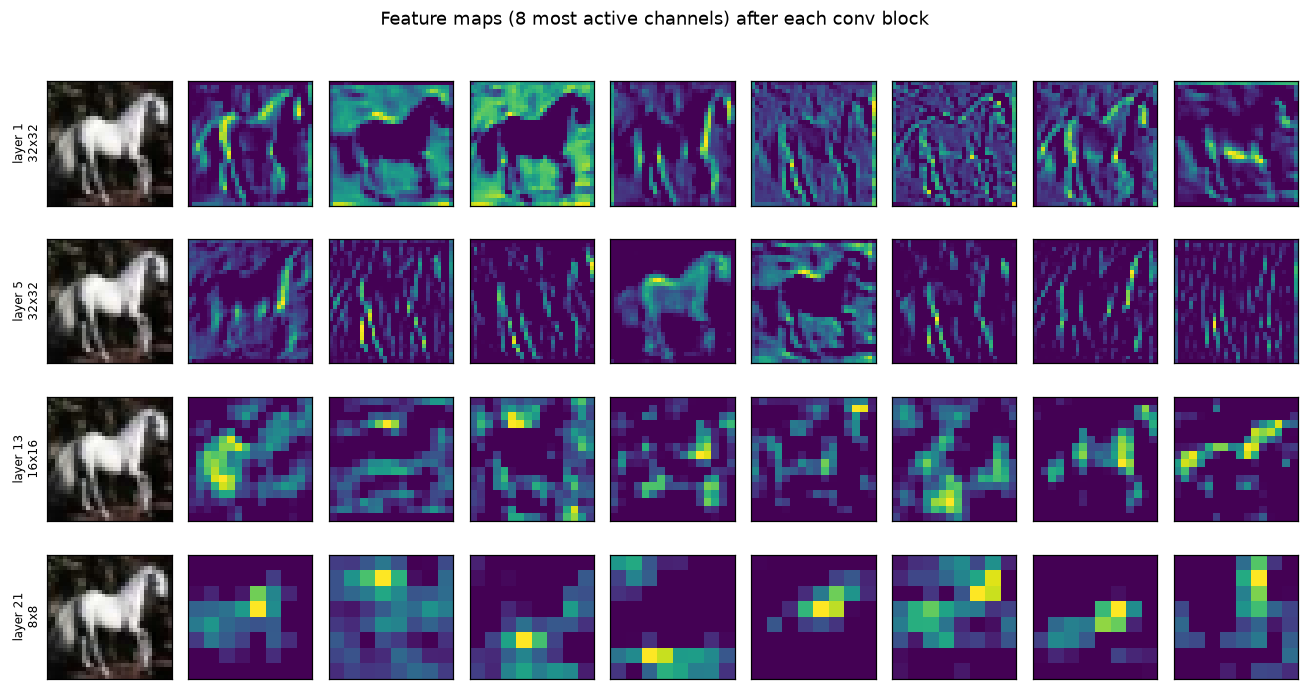

In [21]:
deep = RESULTS["a6_deep_aug_onecycle"]["model"].eval()
w1 = deep.features[0].weight.detach().cpu().numpy()           # (32, 3, 3, 3)
fig, axes = plt.subplots(2, 16, figsize=(12, 1.8))
for ax, k in zip(axes.flat, w1):
    k = (k - k.min()) / (k.max() - k.min() + 1e-8); ax.imshow(k.transpose(1, 2, 0)); ax.axis("off")
plt.suptitle("First conv layer: 32 learned 3x3 RGB kernels (a6_deep_aug_onecycle)", y=1.05)
plt.savefig(FIG / "14_first_layer_filters.png", bbox_inches="tight"); plt.show()

i = int(np.where(y_test == 7)[0][0])                            # a horse from the test set
x1 = data["x_test"][i:i + 1]
pool_idx = [j for j, l in enumerate(deep.features) if isinstance(l, torch.nn.MaxPool2d)]
maps, h = [], x1
with torch.no_grad():
    for j, layer in enumerate(deep.features):
        h = layer(h)
        if j in [1] + [p - 1 for p in pool_idx]: maps.append((j, h[0].cpu().numpy()))
fig, axes = plt.subplots(len(maps), 9, figsize=(12, 1.5 * len(maps) + 0.4))
for r, (j, fmap) in enumerate(maps):
    axes[r, 0].imshow(x_test[i]); axes[r, 0].set_ylabel(f"layer {j}\n{fmap.shape[1]}x{fmap.shape[2]}", fontsize=8)
    top = np.argsort(-fmap.mean((1, 2)))[:8]
    for c, ch in enumerate(top): axes[r, c + 1].imshow(fmap[ch], cmap="viridis")
for ax in axes.flat: ax.set_xticks([]); ax.set_yticks([])
plt.suptitle("Feature maps (8 most active channels) after each conv block", y=1.0); plt.tight_layout()
plt.savefig(FIG / "15_feature_maps.png", bbox_inches="tight"); plt.show()

First-layer kernels are colour blobs and oriented edge detectors — like the hand-made Sobel filters in §5, but learned.
Feature maps go from 32×32 maps that still look like the horse (edges, colour regions, legs) to 16×16 and 8×8 maps that
are abstract: each pixel now "sees" a large part of the image (receptive field grows with depth and pooling) and reacts to
parts such as legs or head rather than to edges.

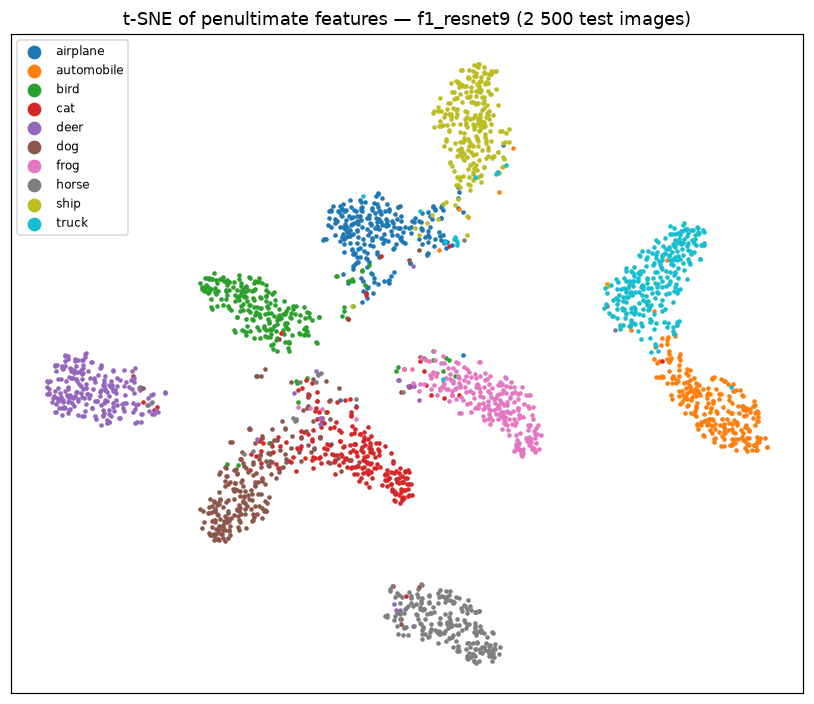

In [22]:
from sklearn.manifold import TSNE
last_fc = [m for m in best.modules() if isinstance(m, torch.nn.Linear)][-1]   # classifier layer
captured = []
hook = last_fc.register_forward_hook(lambda mod, inp, out: captured.append(inp[0].detach().cpu()))
sub = rng.choice(len(y_test), 2500, replace=False)
predict_logits(best, data["x_test"][sub]); hook.remove()
feats = torch.cat(captured).numpy()                                           # inputs of the last layer
emb = TSNE(n_components=2, init="pca", perplexity=30, random_state=SEED).fit_transform(feats)
fig, ax = plt.subplots(figsize=(7.5, 6.5))
for c in range(10):
    m = y_true[sub] == c; ax.scatter(emb[m, 0], emb[m, 1], s=4, label=CLASSES[c], color=plt.cm.tab10(c))
ax.legend(markerscale=4, fontsize=8, loc="best"); ax.set_title(f"t-SNE of penultimate features — {best_name} (2 500 test images)")
ax.set_xticks([]); ax.set_yticks([]); plt.tight_layout(); plt.savefig(FIG / "16_tsne.png"); plt.show()

Penultimate-layer features form 10 clear clusters: the network has turned 3 072 raw pixels into a space where classes are almost linearly separable — that is what the final Dense layer needs. The only clusters that touch are **cat–dog** (and cat touching bird/frog), **airplane–ship** and **truck–automobile**, the same pairs as in the confusion matrix. Vehicles lie on one side, animals on the other.

## 12. Conclusion

1. **Data.** CIFAR-10 is clean and perfectly balanced (5 000/1 000 images per class, all 32×32×3, no duplicates), so accuracy is a fair metric. The difficulty is visual: low resolution, varied poses, similar classes (cat/dog, automobile/truck, airplane/ship).
2. **Why CNNs.** On the same data the baseline MLP reaches 53%, a 2-layer CNN with 22× fewer parameters 70.5%: locality and weight sharing are the right assumptions for images.
3. **What helped** (ablation of the deep CNN, on validation): BatchNorm + Dropout +7.6 pp (they fix overfitting differently and complement each other), augmentation +1.3 pp (and removes overfitting entirely), SGD + OneCycle (with weight decay) +1.3 pp, 2× width +2.6 pp. SE attention gave nothing measurable in the deep net; the +1.5 pp of the small SE network over the simple CNN comes with other architecture changes and does not isolate SE.
4. **Best model:** ResNet-9 with SE blocks, augmentation, OneCycle and label smoothing — **92.6% test accuracy** (baseline deep CNN: 85.2%), loss 0.31. Remaining errors are mostly cat↔dog.
5. **Validation protocol:** model choice on a 5 000-image validation split; test accuracy differs from validation by ≤0.6 pp for every model.
6. **Limitations:** one seed per experiment (differences < 1 pp are within noise); 20 epochs for the ablation (the augmented models were still improving); the Mac ran in Low Power Mode, so the times are not representative.
7. **Next steps:** more epochs, Cutout/MixUp, test-time augmentation (flip), full-width ResNet-9 on a cloud GPU (≈94%). The CIFAR-100 run is in `cifar100_resnet9.ipynb`.